# GEOL 415 Lab 10: Principal Component Analysis (PCA)

For any Chicago Cubs fans, this is a different PCA.

**Learning Objectives:**
- Standardize a multivariate dataset and explain why this is needed before PCA
- Perform PCA with `sklearn` and interpret explained variance and the "elbow" of a scree plot
- Visualize data in principal component space
- Use PCA loadings to determine which original variables drive each component

**Instructions:** Throughout this notebook, replace each `___` with the correct code. Where you see `*Answer:*___`, replace the blank with your written response.

# 0 - Startup

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA

# 1 - Load data

Today we'll be looking at volatile organic compound measurement data (plus some other compounds) taken during the NASA FIREX-AQ campaign in 2019. This campaign consisted of a series of flights through and around smoke plumes in an effort to characterize the composition of the smoke produced by a burning event.

The data below correspond to a single day's worth of flight data, about 12 hours' worth. There are a **lot** of compounds present in this dataset, and it is therefore worth performing some dimensionality reduction on. Load the data below. NOTE: units are in parts per billion by volume (ppbv)

In [2]:
df = pd.read_csv('../Data/voc_fire_data.csv')
df

,Time,HCN,CH3OH,CH3CN,HNCO,CH3CHO,C2H5OH,HCOOH,Acrylonitrile,Acrolein,...,Catecholx5MeFurfural,BenzFuran,C9Aromatics,C6H4O3,Guaiacol,Naphthalene,Creosols,Syringol,C10H30O5Si5,C7H4ClF3
0,63420.0,0.370,6.440,0.148,-0.023,1.046,1.099,3.552,-0.001,0.115,...,-0.007,0.000,0.012,-0.002,0.017,-0.009,0.010,-0.004,-0.004,-0.001
1,63421.0,0.224,6.959,0.144,0.470,1.206,1.146,3.471,0.002,0.098,...,-0.008,0.001,0.004,0.005,0.004,-0.007,-0.008,0.002,0.001,-0.001
2,63422.0,0.453,5.836,0.172,0.015,1.075,0.679,3.200,-0.001,0.131,...,0.059,0.003,0.012,-0.001,0.007,0.004,0.013,0.016,0.001,-0.001
3,63423.0,0.016,5.740,0.166,-0.024,1.126,1.206,3.253,0.004,0.136,...,0.057,-0.003,0.004,0.002,0.015,0.002,0.013,-0.008,-0.001,0.000
4,63424.0,0.478,5.821,0.150,0.021,1.113,0.395,3.231,0.001,0.115,...,0.027,-0.003,0.008,-0.006,0.019,-0.002,0.016,0.001,-0.001,0.004
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
18051,83360.0,0.357,3.538,0.160,-0.143,1.673,4.912,5.427,0.002,0.163,...,0.042,0.010,0.014,0.002,-0.003,0.009,0.022,0.011,0.017,0.063
18052,83361.0,0.173,3.767,0.210,0.426,1.762,2.273,5.299,-0.002,0.116,...,0.003,0.001,-0.003,-0.000,0.019,-0.007,0.006,0.005,0.024,0.060
18053,83362.0,0.288,3.559,0.194,0.244,1.695,3.776,5.835,-0.002,0.134,...,0.024,0.001,0.027,0.003,0.009,-0.002,0.003,0.007,0.013,0.070
18054,83363.0,0.241,3.540,0.144,0.566,1.640,2.271,5.521,-0.001,0.175,...,0.074,0.008,-0.003,0.002,0.006,0.008,0.014,0.002,0.007,0.037


Note we have a time column, which we'll drop out for PCA

In [3]:
# Select every column EXCEPT the first (Time). Hint: iloc[rows, columns]; use a slice for columns.
df_chem = df.iloc[:, 1:]
df_chem.head()

,HCN,CH3OH,CH3CN,HNCO,CH3CHO,C2H5OH,HCOOH,Acrylonitrile,Acrolein,AcetonePropanal,...,Catecholx5MeFurfural,BenzFuran,C9Aromatics,C6H4O3,Guaiacol,Naphthalene,Creosols,Syringol,C10H30O5Si5,C7H4ClF3
0,0.370,6.440,0.148,-0.023,1.046,1.099,3.552,-0.001,0.115,3.845,...,-0.007,0.000,0.012,-0.002,0.017,-0.009,0.010,-0.004,-0.004,-0.001
1,0.224,6.959,0.144,0.470,1.206,1.146,3.471,0.002,0.098,3.904,...,-0.008,0.001,0.004,0.005,0.004,-0.007,-0.008,0.002,0.001,-0.001
2,0.453,5.836,0.172,0.015,1.075,0.679,3.200,-0.001,0.131,3.863,...,0.059,0.003,0.012,-0.001,0.007,0.004,0.013,0.016,0.001,-0.001
3,0.016,5.740,0.166,-0.024,1.126,1.206,3.253,0.004,0.136,3.756,...,0.057,-0.003,0.004,0.002,0.015,0.002,0.013,-0.008,-0.001,0.000
4,0.478,5.821,0.150,0.021,1.113,0.395,3.231,0.001,0.115,3.740,...,0.027,-0.003,0.008,-0.006,0.019,-0.002,0.016,0.001,-0.001,0.004


# 2 - Prepare data - NOW we standardize.

A fundamental assumption of PCA is that it is performed on standardized data. Well, the data really just need to have zero mean. We will standardize (or z-score) our dataframe such that every column is centered around 0 and has unit variance. Define the following function to help with this below:

In [4]:
def z_score(df):
    # subtract the column mean, then divide by the column standard deviation
    return (df - df.mean()) / df.std()

In [5]:
# now standardize the data
df_z = z_score(df_chem) # 
df_z.head()

,HCN,CH3OH,CH3CN,HNCO,CH3CHO,C2H5OH,HCOOH,Acrylonitrile,Acrolein,AcetonePropanal,...,Catecholx5MeFurfural,BenzFuran,C9Aromatics,C6H4O3,Guaiacol,Naphthalene,Creosols,Syringol,C10H30O5Si5,C7H4ClF3
0,0.178552,1.467083,-0.259601,-0.738200,0.222717,-0.170589,0.512843,-0.296163,0.608474,0.315711,...,-0.697793,-0.279003,0.505978,-0.575200,0.802203,-1.322211,0.515256,-0.956909,-0.763976,-0.484615
1,-0.229029,1.653522,-0.306444,0.830074,0.340022,-0.158162,0.478414,0.170815,0.419844,0.337689,...,-0.730784,-0.091666,-0.151183,1.086757,-0.180545,-1.102553,-1.298952,0.068205,-0.297336,-0.484615
2,0.410258,1.250110,0.021454,-0.617319,0.243979,-0.281642,0.363227,-0.296163,0.786009,0.322416,...,1.479661,0.283008,0.505978,-0.337777,0.046243,0.105565,0.817624,2.460138,-0.297336,-0.484615
3,-0.809691,1.215624,-0.048810,-0.741381,0.281370,-0.142297,0.385754,0.482133,0.841488,0.282558,...,1.413678,-0.841013,-0.151183,0.374490,0.651011,-0.114093,0.817624,-1.640319,-0.483992,-0.449407
4,0.480049,1.244722,-0.236180,-0.598233,0.271839,-0.356735,0.376403,0.015156,0.608474,0.276597,...,0.423926,-0.841013,0.177397,-1.524889,0.953395,-0.553408,1.119992,-0.102648,-0.483992,-0.308578


You'll notice some negative values in the dataset. This has to do with how measurement instruments were calibrated during data collection. This is technically unphysical, but is par for the course when dealing with experimental data.

# 3 - PCA

Finally, for the main event. Performing PCA with code is exceedingly straightforward with `sklearn`'s `PCA` class. 

To recap, PCA is an algorithm that performs a linear transformation on an original dataset for the purpose of dimensionality reduction. It snaps the data to a new coordinate system, one which the first coordinate captures the most amount of variance in the dataset. The other coordinates are orthogonal, or perpendicular, to each other, to minimize redundancy. 

In math terms, PCA accomplishes this by performing a singular value decomposition on a data matrix. Equivalently, PCA performs an eigendecomposition on the **covariance matrix** of a particular dataset. The result is a set of vectors that, when multiplied by the original data, produce a transformed dataset.

Below, we will conduct PCA on this data. I have set the number of components to 10. This is arbitrary, but considering the original dimensionality of our VOC data is 42, this is already quite a reduction.

In [6]:
from sklearn.decomposition import PCA

In [7]:
# Create a PCA object with 10 components, then fit it AND transform the standardized data in one step.

# HINT: you need to "fit_transform" the standardized data.
pca = PCA(n_components=10)
df_scaled = pca.fit_transform(df_z)

Below, we'll look at what this actually did for us. Here, `pca` will be used to examine principal components and the variance they encode. The transformed data, `df_scaled`, gives us our data following transformation to our new 10-dimensional data space.

# 4 - Results and interpretation

## 4.1 How much variance is explained by each PC?

Plot 1) the explained variance ratio of the 10 PCs and 2) the cumulative proportion of variance with each successive component below. We'll use `pca.explained_variance_ratio_` for that here.

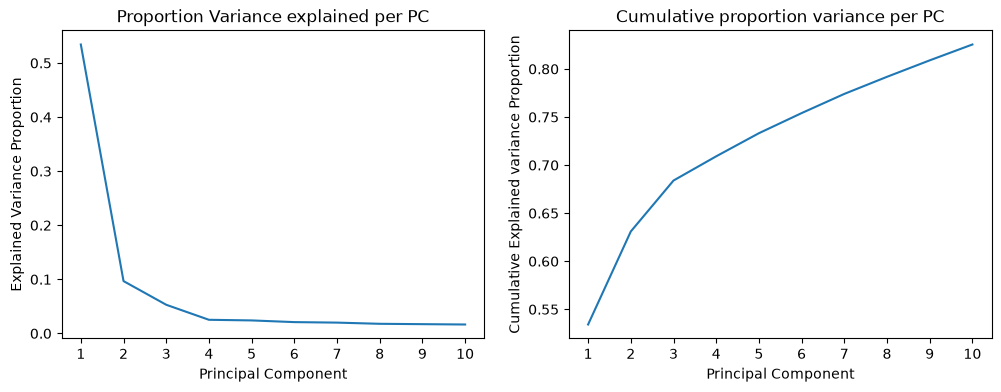

In [8]:
# The fraction of variance explained by each PC is stored in the fitted PCA object
variance_props = pca.explained_variance_ratio_ # check first 10
f, ax = plt.subplots(1,2, figsize=(12,4))

xdata = range(1,len(variance_props)+1)

ax[0].plot(xdata, variance_props)
ax[0].set_xticks(xdata)
ax[0].set_ylabel('Explained Variance Proportion')
ax[0].set_xlabel('Principal Component')
ax[0].set_title('Proportion Variance explained per PC')

# Cumulative variance: running total of variance_props (hint: np.cumsum)
ax[1].plot(xdata, np.cumsum(variance_props))
ax[1].set_xticks(xdata)
ax[1].set_ylabel('Cumulative Explained variance Proportion')
ax[1].set_xlabel('Principal Component')
ax[1].set_title('Cumulative proportion variance per PC')

plt.show()

**Question**: Where do you see the "elbow" in the left-hand plot? Give me either a single PC or a range of PC. After the "elbow" the left-hand plot flatlines. In words, what does this mean about the variance encoded in each subsequent principal component?

*Answer:* The elbow is around PC3–PC4, after which the curve becomes nearly flat. Each additional component explains only a small amount of the total variance, so adding more components provides less additional information.


**Question**: What is the cumulative variance explained by the first 4 PCs?

*Answer*: The first four PCs explain approximately ~ 70% of the total variance, based on the plot.

## 4.2 What do the first two PCs look like?

We have a nice elbow plot above. The point of PCA is to be able to conceptualize what is going on in a given dataset in a lower dimension. Let's visualize the relationship between PC1 and PC2 below

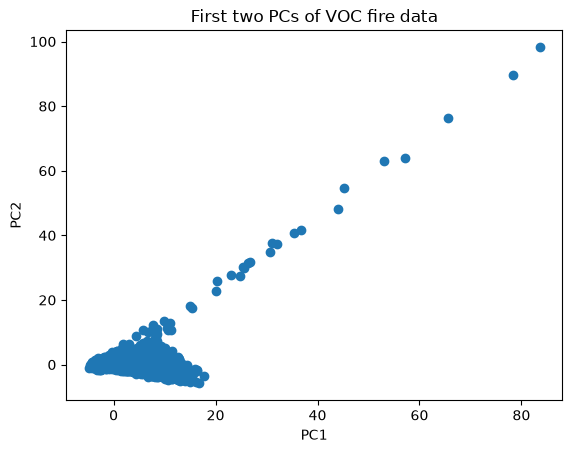

In [9]:
# PC2 vs PC1 (Remember that Python indexes from 0: column 0 is PC1)
plt.subplots()
plt.scatter(df_scaled[:, 0], df_scaled[:, 1])
plt.xlabel('PC1')
plt.ylabel('PC2')
plt.title('First two PCs of VOC fire data')
plt.show()

**Question**: Describe the relationship between PC1 and PC2. What stands out to you?

*Answer:* Most points cluster near the origin, while a smaller group forms a branch extending toward high positive PC1 and PC2 values. Several extreme observations stand out. Although this branch slopes upward, the two components are uncorrelated across the full dataset.


**Question:** In the code cell below, plot the 3rd and 4th principal components against each other. In the markdown cell below, describe what you see. "I don't know" is an acceptable answer here

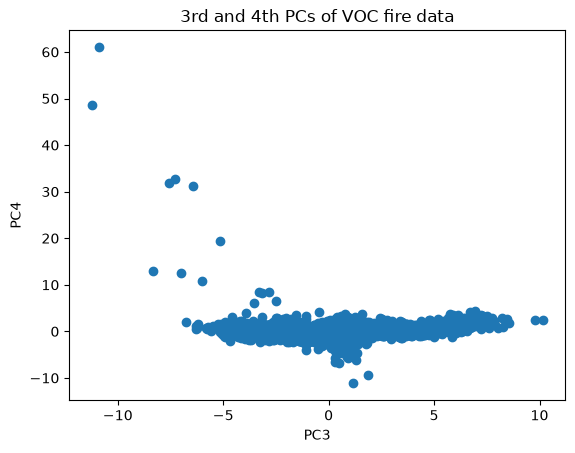

In [10]:
# PC3 vs PC4
plt.subplots()
plt.scatter(df_scaled[:, 2], df_scaled[:, 3])
plt.xlabel('PC3')
plt.ylabel('PC4')
plt.title('3rd and 4th PCs of VOC fire data')
plt.show()

*Answer*: Most points form a horizontal band around PC4 = 0. A few observations have unusually high PC4 values and negative PC3 values. There is no clear overall linear relationship.

## 4.3 What is in each principal component?

A drawback of PCA is that our dataset has been transformed such that each axis is actually a combination of a lot of different features from our dataset. As you saw from above, this can be an issue where interpretability is concerned. Whereas our original dataset shows 1 chemical species per dimension, PCA has combined these in varying ways to produce the new Principal Components. 

Let's get a sense of what chemical compounds contribute most to the first two PCs

In [11]:
num_pcs = 2

# for each PC, let's look at the top 10 vector components (loadings) that contribute to that PC.
# pca.components_[pc] holds the loadings for that PC; we rank by absolute value (sign doesn't matter for importance).
for pc in range(num_pcs):
    ranked_loadings = np.argsort(np.abs(pca.components_[pc]))[::-1][:10]
    print(f"Top 10 loadings for PC{pc+1}:")
    print(df_z.columns[ranked_loadings])
    print("\n")

Top 10 loadings for PC1:
Index(['Acrolein', 'C3H6O2', 'x23Butanedione', 'C4Carbonyls', 'CH3CHO',
       'AcetonePropanal', 'Benzene', 'Toluene', 'HCOOH', 'DimeFurans'],
      dtype='str')


Top 10 loadings for PC2:
Index(['Acrylonitrile', 'C4H5N', 'CH3CN', 'BenzNitrile', 'Furfural', 'Phenol',
       'C7H4ClF3', 'C2H5OH', 'HCN', 'Furan'],
      dtype='str')




Let's also see what contributes LEAST to each PC.

In [12]:
num_pcs = 2

# for each PC, let's look at the 5 vector components (loadings) that contribute LEAST to that PC.
# Hint: argsort sorts smallest -> largest, so you don't need to reverse the order this time.
for pc in range(num_pcs):
    ranked_loadings = np.argsort(np.abs(pca.components_[pc]))[:5]
    print(f"Bottom 5 loadings for PC{pc+1}:")
    print(df_z.columns[ranked_loadings])
    print("\n")

Bottom 5 loadings for PC1:
Index(['Styrene', 'C6H4O3', 'Syringol', 'DMS', 'C4H5N'], dtype='str')


Bottom 5 loadings for PC2:
Index(['Acrolein', 'x2MeFuranx3MeFuran', 'MaleicAnhyd', 'Naphthalene',
       'CH3NO2'],
      dtype='str')




**Question:** What do you notice about the top contributors here? Is there any overlap between the top 10 loadings for PCs 1 and 2? How about any crossover between top and bottom loadings?

HINTS: Compounds like benzene, toluene, and acrolein are commonly associated with fresh smoke, or smoke that has been more recently emitted. Species like Styrene are associated with combustion of synthetics. DMS, or dimethyl sulfide, is primarily emitted by ocean biota and are not typically associated with fire emissions.

**Ans:** PC1 includes fresh-smoke compounds such as acrolein, benzene, and toluene. PC2 includes several nitrogen-containing compounds, such as acrylonitrile, CH3CN, and HCN.

There is no overlap between the top 10 contributors to PC1 and PC2. However, acrolein is a top contributor to PC1 but a bottom contributor to PC2, while C4H5N shows the opposite pattern. This suggests that the two PCs capture different patterns of chemical variation.

## Mini-Evals (please fill out!!!)

1. Please rate 1-5 how this lab was for you. 1 := this was too difficult, 5 := I could do this in my sleep.

*Answer*: 3

2. What is something you wished I covered in this lab? 

*Answer*: Filling in the blanks was not too difficult, but more explanation with documentation of the concepts would have been helpful.

# Lab submission


Please `Restart` and `Run All` on this notebook and submit this lab when you are done!